In [ ]:
!pip install -q kaggle

Instal library kaggle di phyton

In [ ]:
!mkdir -p ~/.kaggle

Membuat folder .kaggle sebagai tempat menyimpan file konfigurasi Kaggle

In [ ]:
!cp kaggle.json ~/.kaggle

Menyalin file kaggle.json ke folder .kaggle

In [ ]:
!chmod 600 ~/.kaggle/kaggle.json

File API kaggle

In [ ]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
 98% 2.26G/2.29G [00:15<00:00, 217MB/s]
100% 2.29G/2.29G [00:15<00:00, 155MB/s]


Dowload dataset dari kaggle ke phyton

In [ ]:
!unzip chest-xray-pneumonia.zip

Output streaming akan dipotong hingga 5000 baris terakhir.
  inflating: chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0444-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0445-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0446-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0447-0001.jpeg  
  in

Mengekstrak file chest-xray-pneumonia.zip menjadi folder berisi dataset

In [ ]:
import os
os.listdir("/content")

['.config',
 'chest_xray',
 'kaggle.json',
 'chest-xray-pneumonia.zip',
 'sample_data']

*   import os → memanggil library bawaan Python untuk urusan file & folder
*   os.listdir("/content") → menampilkan daftar file dan folder yang ada di folder utama

In [ ]:
import os, shutil

base_dir = "/content/chest_xray"
all_dir = "/content/chest_xray_all"

for cls in ["NORMAL", "PNEUMONIA"]:
    os.makedirs(f"{all_dir}/{cls}", exist_ok=True)

for split in ["train", "val", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        src = f"{base_dir}/{split}/{cls}"
        dst = f"{all_dir}/{cls}"
        for img in os.listdir(src):
            shutil.copy(os.path.join(src, img), dst)

*   import os, shutil : akses file untuk di copy
*   base_dir : folder dataset asli
*   all_dir : folder baru hasil gabungan
*   for cls in : membuat folder Normal dan Pneumonia
*   for split in : mengambil semua bagian dataset
*   src dan dst : tentukan sumber dan tujuan
*   for img in : Ambil semua gambar dari folder sumber dan copy ke folder tujuan
* syntax ini bertujuan menggabungkan semua data (train, val, test) menjadi satu dataset besar berdasarkan kelas, digunakan untuk splitting ulang dataset.

In [ ]:
source_dir = "/content/chest_xray_all"
target_dir = "/content/dataset/chest_xray"

In [ ]:
import random
import numpy as np
import tensorflow as tf

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)


* import random : memanggil phyton
import numpy as np : memanggil array/matriks
import tensorflow as tf : memanggil di model deep learning
* 42 hanya angka awal untuk generator angka acak, fungsinya untuk hasil random jadi konsisten. Angka 42  populer karena budaya programmer, terutama dari buku The Hitchhiker's Guide to the Galaxy.


In [ ]:
splits = {
    "train": 0.70,   # ganti sesuai kebutuhan
    "val": 0.15,
    "test": 0.15
}

random.seed(42)

# Buat folder
for split in splits:
    for cls in ["NORMAL", "PNEUMONIA"]:
        os.makedirs(f"{target_dir}/{split}/{cls}", exist_ok=True)

# Split per kelas
for cls in ["NORMAL", "PNEUMONIA"]:
    images = os.listdir(f"{source_dir}/{cls}")
    random.shuffle(images)

    n = len(images)
    n_train = int(splits["train"] * n)
    n_val   = int(splits["val"] * n)

    train_imgs = images[:n_train]
    val_imgs   = images[n_train:n_train+n_val]
    test_imgs  = images[n_train+n_val:]

    for img in train_imgs:
        shutil.copy(f"{source_dir}/{cls}/{img}",
                    f"{target_dir}/train/{cls}/{img}")

    for img in val_imgs:
        shutil.copy(f"{source_dir}/{cls}/{img}",
                    f"{target_dir}/val/{cls}/{img}")

    for img in test_imgs:
        shutil.copy(f"{source_dir}/{cls}/{img}",
                    f"{target_dir}/test/{cls}/{img}")


* splits : pembagian data
* for split in splits : membuat struktur
* for cls : split dilakukan perkelas
* images = os.listdir : ambil semua gambar secara acak berurutan
* n = len(images) : hitung jumlah data train dan val sisanya masuk kes data testing
* train_imgs : membagi data dan copy ke folder masing masing

In [ ]:
for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    for cls in ["NORMAL", "PNEUMONIA"]:
        print(cls, len(os.listdir(f"/content/dataset/chest_xray/{split}/{cls}")))



TRAIN
NORMAL 1108
PNEUMONIA 2991

VAL
NORMAL 237
PNEUMONIA 640

TEST
NORMAL 238
PNEUMONIA 642


mengecek jumlah data gambar disetiap folder

In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras import layers, models, backend as K
from tensorflow.keras.layers import Layer, Lambda
from tensorflow.keras.preprocessing.image import ImageDataGenerator

* from tensorflow import keras : menampilkan API yang lebih simpel untuk bikin model
* import matplotlib.pyplot as plt : menampilkan grafik
* from tensorflow.keras import layers, models : membuat layer untuk menyusun model
* backend as K : operasi matematika di belakang layar
* lamda : fungsi
* ImageDataGenerator : load dataset gambar dari folder, resize gambar, augmentasi


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 128
BATCH_SIZE = 16

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    zoom_range=0.05
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    "/content/dataset/chest_xray/train",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_generator = val_test_datagen.flow_from_directory(
    "/content/dataset/chest_xray/val",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    "/content/dataset/chest_xray/test",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=False
)


Found 4099 images belonging to 2 classes.
Found 877 images belonging to 2 classes.
Found 880 images belonging to 2 classes.


* Semua gambar diubah menjadi 128×128 pixel dan diproses 16 gambar sekali jalan
* normalisasi rescale 1/255 mengubah 0-255 menjadi 0-1, serta augmentasi seperti rotasi kecil dan zoom untuk meningkatkan variasi data dan mencegah overfitting, sedangkan pada data validasi dan testing hanya dilakukan normalisasi tanpa augmentasi agar evaluasi tetap objektif. Fungsi flow_from_directory kemudian digunakan untuk membaca gambar berdasarkan struktur folder Normal dan Pneumonia, mengubahnya menjadi format numerik, menggunakan mode grayscale karena citra x-ray tidak memerlukan warna, serta mengatur label dalam bentuk kategorikal.

In [ ]:
import cv2

path = "/content/dataset/chest_xray/train/PNEUMONIA/person278_virus_573.jpeg"
img = cv2.imread(path, 0)  # grayscale

print("Shape:", img.shape)
print(img[0:5, 0:5])

Shape: (1072, 1296)
[[41 41 35 28 30]
 [36 39 38 32 31]
 [35 39 40 34 29]
 [38 41 39 34 31]
 [38 40 36 34 46]]


* Mengimpor library OpenCV : membaca gambar dan mengolah citra (resize, filter, dll)
* path : lokasi file gambar pneumonia untuk contoh analisis
* shape : menampilkan ukuran gambar
* shape (1072, 1296) dalam output terdapat 1072 baris dan 1296 kolom, tetapi dalam syntax yg diambil hanyi 5 baris dan 5 kolom.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(train_generator.classes)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_generator.classes
)

class_weights = dict(zip(classes, class_weights))
print("Class weights:", class_weights)


Class weights: {np.int32(0): np.float64(1.8497292418772564), np.int32(1): np.float64(0.6852223336676697)}


* from sklearn : menghitung kelas otomatis
* numpy : untuk operasi aray atau matriks
* classes : mengambil label unik, misal [0,1], 0 normal , 1 pneumonia
* class_weights : hitung kelas weights
* class weight digunakan pada saat training untuk mempengaruhi perhitungan loss.

In [ ]:
inputs = keras.Input(shape=(128, 128, 1))  # grayscale
conv_layer = layers.Conv2D(
    filters=256,
    kernel_size=9,
    strides=4,
    activation='relu'
)(inputs)

* model menerima gambar baris dan kolom 128 dan 1 chanel grayscale
* convolution layer (ekstraksi fitur awal) akan menghasilkan 256 feature map dengan kernel 9 baris dan 9 kolom (9x9) dan bergeser ke kenan sejauh 4
* jadi akan menghasilkan sebnayk 256 feature maps dengan satu ukuran featur maps 30x30, ini di dapatkan dengan rumus N-F/S+1= 128-9/4+1=30.75 karena kernel harus pas tidak boleh keluar dari gambar maka dibulatkan ke bawa menjadi 30. +1 karena posisi awal dihitung.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def squash(vectors, axis=-1):
    s_squared_norm = tf.reduce_sum(tf.square(vectors), axis, keepdims=True)
    scale = s_squared_norm / (1 + s_squared_norm)
    return scale * vectors / tf.sqrt(s_squared_norm + keras.backend.epsilon())

inputs = keras.Input(shape=(128, 128, 1))  # ini jangan dihapus
x = layers.Conv2D(filters=32 * 8, kernel_size=9, strides=4, activation='relu')(inputs)
x = layers.Reshape([-1, 8])(x)
primary_caps = layers.Lambda(lambda v: squash(v))(x)
print(primary_caps.shape)


(None, 28800, 8)


Output dari layer konvolusi dengan ukuran 30×30×256 kemudian diubah menjadi bentuk kapsul melalui proses reshape menjadi (28800, 8), di mana setiap kapsul direpresentasikan sebagai vektor berdimensi 8. Selanjutnya, fungsi squash digunakan untuk menormalkan panjang vektor sehingga berada pada rentang 0 hingga 1 tanpa mengubah arah vektor.8 dimensi yg artinya 1 kapsul= 8 angka. Dimensi mewakili elemen bentuk, ukuran,posisi tekstur.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def squash(vectors, axis=-1):
    s_squared_norm = tf.reduce_sum(tf.square(vectors), axis, keepdims=True)
    scale = s_squared_norm / (1 + s_squared_norm)
    return scale * vectors / tf.sqrt(s_squared_norm + keras.backend.epsilon())

class DigitCapsule(layers.Layer):
    def __init__(self, num_capsule, dim_capsule, routings=3, **kwargs):
        super().__init__(**kwargs)
        self.num_capsule = num_capsule
        self.dim_capsule = dim_capsule
        self.routings = routings

    def build(self, input_shape):
        self.input_num_capsule = input_shape[1]
        self.input_dim_capsule  = input_shape[2]

        self.W = self.add_weight(
            shape=[self.input_num_capsule, self.num_capsule, self.input_dim_capsule, self.dim_capsule],
            initializer='glorot_uniform',
            trainable=True,
            name='W_caps'
        )

    def call(self, inputs):
        batch_size = tf.shape(inputs)[0]
        inputs_expand = tf.expand_dims(tf.expand_dims(inputs, 2), -2)
        W_tiled = tf.tile(tf.expand_dims(self.W, 0), [batch_size,1,1,1,1])

        u_hat = tf.matmul(inputs_expand, W_tiled)
        u_hat = tf.squeeze(u_hat, axis=-2)

        b = tf.zeros_like(u_hat[:,:,:,0])

        for i in range(self.routings):
            c = tf.nn.softmax(b, axis=2)
            s = tf.reduce_sum(c[...,None] * u_hat, axis=1)
            v = squash(s)
            if i < self.routings - 1:
                b += tf.reduce_sum(u_hat * v[:,None,:,:], axis=-1)

        return v

def margin_loss(y_true, y_pred):
    lamb, m_plus, m_minus = 0.5, 0.9, 0.1
    L = y_true * tf.square(tf.maximum(0., m_plus - y_pred)) + \
        lamb * (1 - y_true) * tf.square(tf.maximum(0., y_pred - m_minus))
    return tf.reduce_mean(tf.reduce_sum(L, axis=1))

def CapsNet(input_shape, n_class, routings=3):
    inputs = keras.Input(shape=input_shape)

    x = layers.Conv2D(64, 5, activation='relu', padding='same')(inputs)
    x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
    x = layers.Conv2D(256, 3, strides=2, activation='relu', padding='same')(x)

    primary = layers.Conv2D(32 * 8, 1, activation='relu')(x)
    primary = layers.Reshape([-1, 8])(primary)
    primary = layers.Lambda(lambda v: squash(v))(primary)

    digitcaps = DigitCapsule(n_class, 16, routings=routings)(primary)
    out_caps = layers.Lambda(lambda z: tf.sqrt(tf.reduce_sum(tf.square(z), axis=-1)))(digitcaps)

    return keras.Model(inputs, out_caps, name="CapsNet")

IMAGE_SIZE = 128
NUM_CLASSES = 2

model = CapsNet((IMAGE_SIZE, IMAGE_SIZE, 1), NUM_CLASSES)
model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss=margin_loss,
              metrics=['accuracy'])

model.summary()


Model: "CapsNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 64)   │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 256)    │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 131072, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 131072, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ digit_capsule (DigitCapsule)    │ (None, 2, 16)          │    33,554,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,990,912 (129.67 MB)

 Trainable params: 33,990,912 (129.67 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=30,
    #class_weight=class_weights  # pakai class weight kamu
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 119s 361ms/step - accuracy: 0.7525 - loss: 0.2317 - val_accuracy: 0.9190 - val_loss: 0.0710
Epoch 2/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 58s 226ms/step - accuracy: 0.8986 - loss: 0.0783 - val_accuracy: 0.9407 - val_loss: 0.0504
Epoch 3/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 60s 231ms/step - accuracy: 0.9345 - loss: 0.0563 - val_accuracy: 0.9407 - val_loss: 0.0557
Epoch 4/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 60s 233ms/step - accuracy: 0.9231 - loss: 0.0536 - val_accuracy: 0.9464 - val_loss: 0.0567
Epoch 5/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 60s 234ms/step - accuracy: 0.9369 - loss: 0.0524 - val_accuracy: 0.9464 - val_loss: 0.0512
Epoch 6/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 61s 236ms/step - accuracy: 0.9474 - loss: 0.0451 - val_accuracy: 0.9590 - val_loss: 0.0440
Epoch 7/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 61s 235ms/step - accuracy: 0.9528 - loss: 0.0421 - val_accuracy: 0.9453 - val_loss: 0.0411
Epoch 8/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 60s 234ms/step - accuracy: 0.9494 - loss: 

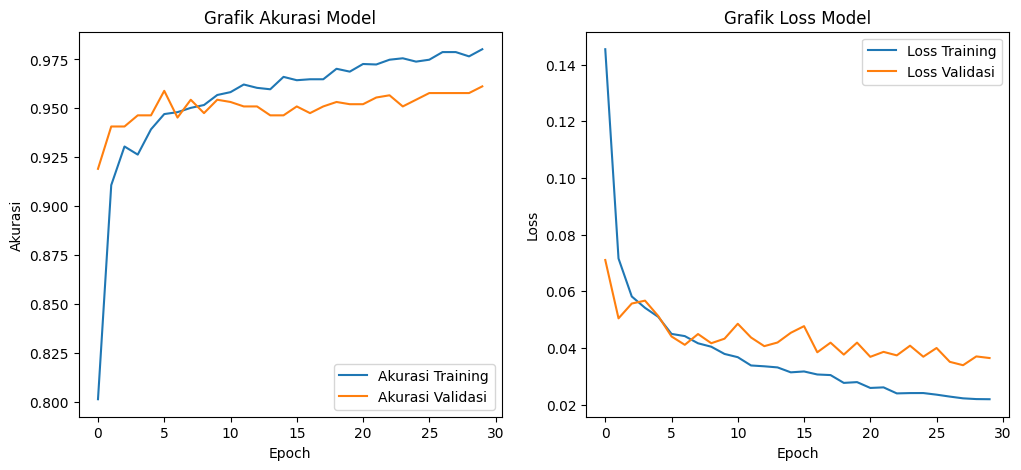

In [ ]:
plt.figure(figsize=(12, 5))

# Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Akurasi Training')
plt.plot(history.history['val_accuracy'], label='Akurasi Validasi')
plt.title('Grafik Akurasi Model')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Loss Training')
plt.plot(history.history['val_loss'], label='Loss Validasi')
plt.title('Grafik Loss Model')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

55/55 ━━━━━━━━━━━━━━━━━━━━ 6s 106ms/step - accuracy: 0.9526 - loss: 0.0433
Test Accuracy: 0.9636363387107849


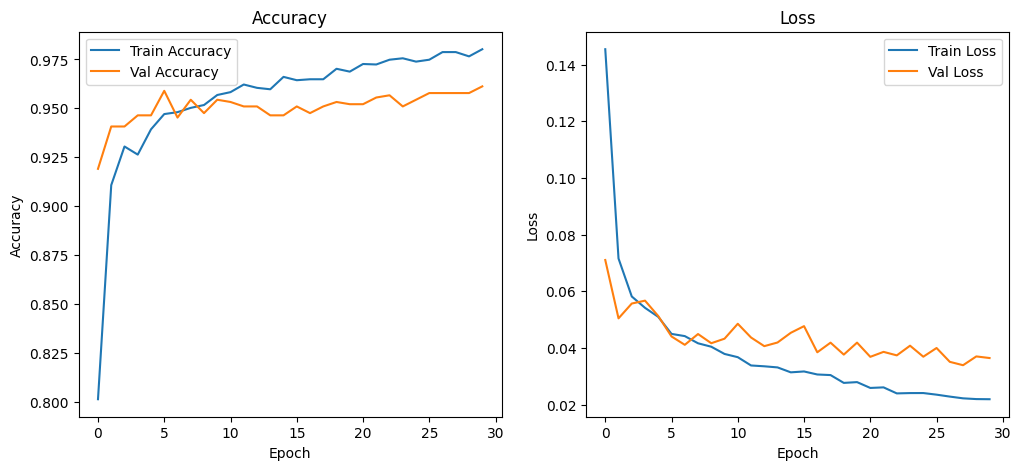

In [ ]:
# ===============================
# Evaluasi test set
# ===============================
test_loss, test_acc = model.evaluate(test_generator)
print("Test Accuracy:", test_acc)

# ===============================
# Plot Learning Curve
# ===============================
plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()


55/55 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step


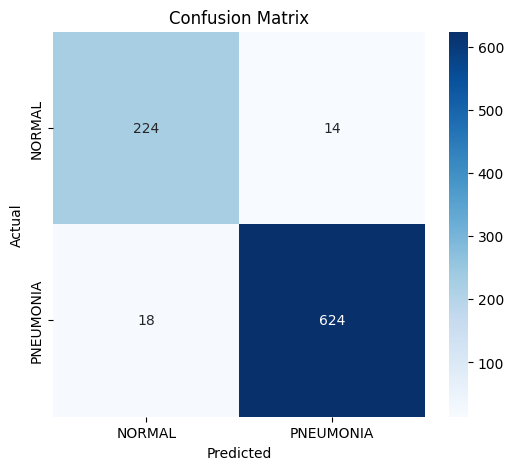

Classification Report:
               precision    recall  f1-score   support

      NORMAL       0.93      0.94      0.93       238
   PNEUMONIA       0.98      0.97      0.97       642

    accuracy                           0.96       880
   macro avg       0.95      0.96      0.95       880
weighted avg       0.96      0.96      0.96       880



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# ===============================
# Prediksi test set
# ===============================
# Model output berupa probabilitas per kelas (panjang vektor kapsul)
y_pred_probs = model.predict(test_generator)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# True labels dari test generator
y_true = test_generator.classes

# ===============================
# Confusion Matrix
# ===============================
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=test_generator.class_indices.keys(),
            yticklabels=test_generator.class_indices.keys())
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# ===============================
# Classification Report
# ===============================
report = classification_report(y_true, y_pred_classes, target_names=test_generator.class_indices.keys())
print("Classification Report:\n", report)


1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step


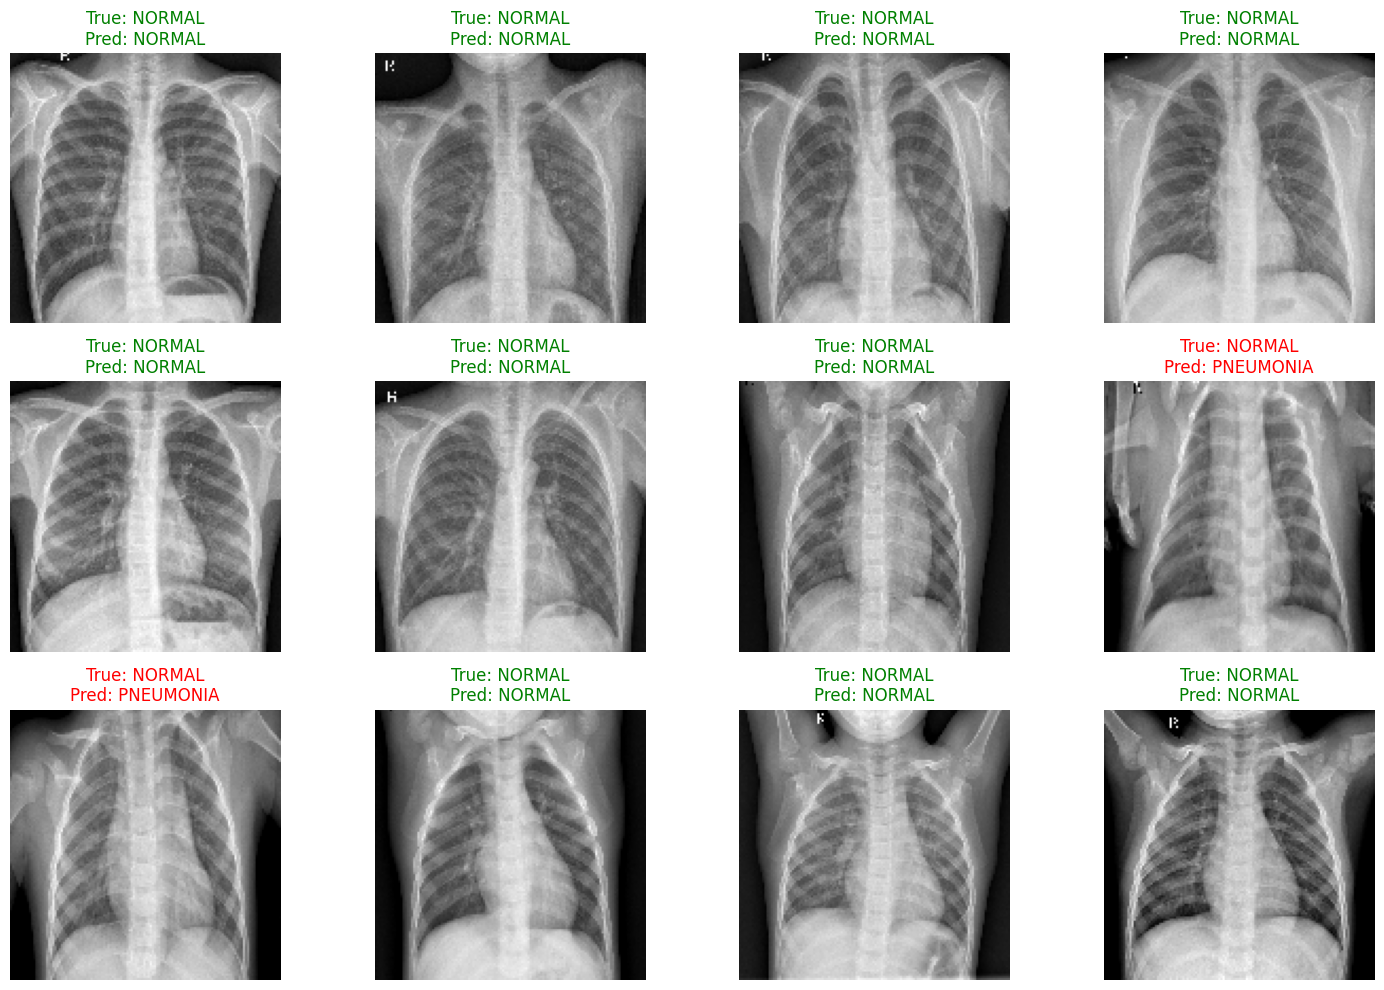

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ambil beberapa batch dari test_generator
test_generator.reset()
x_test, y_test = next(test_generator)

# Prediksi dengan model
y_pred_probs = model.predict(x_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Nama kelas
class_names = list(test_generator.class_indices.keys())

# Tampilkan 12 contoh citra
plt.figure(figsize=(15,10))
for i in range(12):
    plt.subplot(3,4,i+1)
    plt.imshow(x_test[i].reshape(IMG_SIZE, IMG_SIZE), cmap='gray')
    plt.axis('off')

    # Judul = label asli + prediksi
    true_label = class_names[y_true_classes[i]]
    pred_label = class_names[y_pred_classes[i]]

    # Kalau prediksi benar hijau, salah merah
    color = 'green' if y_true_classes[i] == y_pred_classes[i] else 'red'
    plt.title(f'True: {true_label}\nPred: {pred_label}', color=color)

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


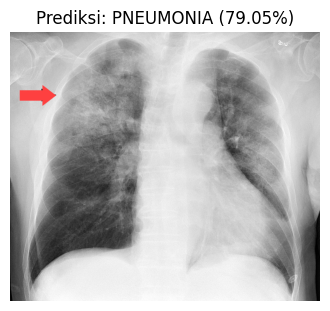

Hasil Prediksi: PNEUMONIA (Keyakinan: 79.05%)


In [ ]:
import requests
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# URL gambar
url = "https://upload.wikimedia.org/wikipedia/commons/8/81/Chest_radiograph_in_influensa_and_H_influenzae%2C_posteroanterior%2C_annotated.jpg"
local_path = "test_xray.jpg"

# --- Unduh gambar ke lokal ---
r = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'})
with open(local_path, 'wb') as f:
    f.write(r.content)

# --- Fungsi preprocessing (disesuaikan ukuran dataset kamu: 128x128 grayscale) ---
def load_image_local(img_path):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (128, 128))  # ✅ sesuaikan dengan model kamu
    img = img.astype('float32') / 255.0
    img = np.expand_dims(img, axis=-1)  # tambahkan channel grayscale
    img = np.expand_dims(img, axis=0)   # tambahkan batch dimension
    return img

# --- Prediksi ---
def predict_local(model, img_path):
    img = load_image_local(img_path)
    prediction = model.predict(img)
    class_idx = np.argmax(prediction, axis=1)[0]
    confidence = np.max(prediction) * 100
    categories = ['NORMAL', 'PNEUMONIA']

    plt.figure(figsize=(4, 4))
    img_display = Image.open(img_path)
    plt.imshow(img_display, cmap='gray')
    plt.axis('off')
    plt.title(f"Prediksi: {categories[class_idx]} ({confidence:.2f}%)")
    plt.show()

    print(f"Hasil Prediksi: {categories[class_idx]} (Keyakinan: {confidence:.2f}%)")

# --- Jalankan prediksi ---
predict_local(model, local_path)